# 이진 분류 실험 ⑨ — GNN 구조 장치 비교 (reverse MP · port numbering · ego ID)
피처는 **공통 17종(내 버전 20열)** 으로 고정하고, Multi-GNN 의 세 장치를 **하나씩 켜 가며** GINe 성능이 얼마나 오르는지 본다. HI-Large, 시드 1개.

| 조건 | reverse MP | port numbering | ego ID | 비고 |
|---|:-:|:-:|:-:|---|
| `plain` | ✕ | ✕ | ✕ | 정방향 메시지만 쓰는 기본 GINe |
| `rev` | ○ | ✕ | ✕ | + 역방향 메시지 전달 |
| `rev_port` | ○ | ○ | ✕ | + `in_port` · `out_port` |
| `rev_port_ego` | ○ | ○ | ○ | + ego ID (= 01 ~ 06 과 같은 구성) |

켜는 순서는 Multi-GNN 논문(Egressy et al., 2024) 의 ablation 표와 같다 (GIN → +ReverseMP → +Ports → +EgoIDs).

같은 20열로 **트리(LightGBM · XGBoost)** 도 돌려 참고 행으로 둔다 (5.1 절) — 같은 입력에서 GNN 이 트리보다 뭘 더 하는지 보는 기준

**끄는 방법** (`bc_lib.Config` 의 스위치 — 이번에 추가)
- `use_reverse_mp=False`: `rev_to` 이웃을 뽑지 않고(이웃 수 0), 모델도 `rev` 쪽 층을 만들지 않는다
- `use_ports=False`: `in_port` · `out_port` 열을 0 으로 둔다 (z-norm 뒤의 0 = 평균값이라 정보가 없다. 모델 구조는 그대로)
- `use_ego=False`: ego ID 열을 0 으로 둔다

**피처** — 결제방식(`payment_format`) 과 절대 시각(`timestamp`) 은 넣지 않는다 (07 · 08 결과)

| 묶음 | 열 | 출처 |
|---|---|---|
| 금액 2 | `amount_received`, `received_currency` | 01 |
| 같은 쌍 이력 4 | `pair_prior_count`, `pair_gap_minutes`, `pair_count_1h`, `reverse_history_count` | 02 |
| 1시간 건수 2 | `src_out_1h`, `dst_in_1h` | 03 |
| 계좌 이력 · 평소 대비 12 | `hist_out/in`, `hist_uniq_out/in`, `active_days`, `rate_vs_prior`, `minute_burst`, `gap_minutes` (송신 · 수신) | 06 |

- 계좌 누적 값(`hist_*`, `active_days`) 은 **거래마다 그 전날까지** 센 값을 엣지에 붙인 것이다. 공유 그래프에서는 노드 값이 계좌당 하나뿐이라 날짜별 값을 노드에 넣을 수 없어서 엣지에 싣는다. 08 의 v10 노드 피처(구간 끝 기준) 와 달리 미래 정보가 없다
- 학습 설정은 06 과 같다 (이웃 [100, 100], 배치 2048, 에폭 = 256 배치, 검증 4 에폭마다, patience 8, 검증 AP 로 선택). 마지막 조건 `rev_port_ego` 는 06 의 GINe 에서 피처만 바꾼 것이다
- **시드가 하나다.** 06 의 GINe 는 최고점(28 에폭, 검증 AP 0.588) 뒤에도 검증 AP 가 0.569 ~ 0.586 사이를 오갔다. 조건 간 차이가 0.02 안쪽이면 판단하지 않는다
- 예상 시간: 06(예전 서버) 은 에폭당 171초 · 60 에폭 학습 3.9시간 + 테스트 전체 추론 2.3시간이었다 → 조건 4개에 하루 안팎. `plain` 은 역방향 이웃을 안 뽑아 더 빠르다

## 0. 작업 준비

In [1]:
import sys, json, time, gc, dataclasses
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.append(str(Path.cwd()))
import bc_lib as B
L = B.L

In [2]:
# ---- 공통 설정(plan.md) 과 다른 점 ------------------------------------------
# - 비교 변수 : reverse MP · port numbering · ego ID 를 하나씩 켠다 (공통 설정과 같은 구성은 rev_port_ego 뿐)
# - 이웃      : reverse MP 를 끈 plain 은 정방향(to) 이웃만 2홉 × 100. 나머지는 방향별 100
# - 피처      : 공통 17종의 내 버전 20열 + port 2열. payment_format · 절대 시각(timestamp) 은 넣지 않는다
# - 누수 규칙 : 계좌 · 쌍 이력은 창이 아니라 "전날까지 누적" 으로 간다 (06 과 같음. plan.md 의 "누적 금지" 와 다르다)
#     누적 : hist_out/in, hist_uniq_out/in, active_days, rate_vs_prior 의 분모(과거 일평균), pair_prior_count, reverse_history_count
#     창   : src_out_1h, dst_in_1h, pair_count_1h, minute_burst, rate_vs_prior 의 분자(최근 24h)
#     미래 정보는 없다 (거래 시각 기준 과거만). 대신 누적 값은 날짜가 갈수록 커지는 드리프트가 있다 (04_node_count_drift)
# - 시드 1개(42), 추론 배치 2048 (06 과 같음). 메모리 한도는 새 서버 기준 약 48GB
# - 그 외 (데이터 · 분할, 그래프 범위, 가중 CE, 에폭 · 검증 · patience, 검증 표본, z-norm) 는 공통 설정과 같다
# ---- 실험 설정 ------------------------------------------------------------
SMOKE = False                     # True: 에폭 2 · 에폭당 8 배치 · 검증/테스트 일부만으로 끝까지 한 번 (에러 잡기용). 결과는 gnn_structure_smoke/ 에 따로
RUN_NAME = 'gnn_structure' + ('_smoke' if SMOKE else '')
cfg = B.Config(dataset='HI-Large', smoke=SMOKE, eval_batch_size=2048)   # 06 과 같은 설정. 구조 스위치는 조건마다 dataclasses.replace 로 바꿔 넣는다
B.seed_all(cfg.seed)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR = cfg.out_dir(RUN_NAME)

AMOUNT_FEATURES = ['amount_received', 'received_currency']
PAIR_FEATURES = ['pair_prior_count', 'pair_gap_minutes', 'pair_count_1h', 'reverse_history_count']
ACT_FEATURES = ['src_out_1h', 'dst_in_1h']                # 03 의 8개 중 공통(1시간 건수) 2개만
HIST_FEATURES = ['src_hist_out', 'src_hist_uniq_out', 'src_active_days', 'src_rate_vs_prior', 'src_minute_burst', 'src_gap_minutes',
                 'dst_hist_in', 'dst_hist_uniq_in', 'dst_active_days', 'dst_rate_vs_prior', 'dst_minute_burst', 'dst_gap_minutes']
BASE_FEATURES = AMOUNT_FEATURES + PAIR_FEATURES + ACT_FEATURES + HIST_FEATURES      # 공통 17종의 내 버전 (20열)
GNN_FEATURES = BASE_FEATURES + B.PORT_FEATURES                                      # 피처 행렬 열 순서 (22). port 는 맨 뒤 두 열
PORT_COLS = [GNN_FEATURES.index('in_port'), GNN_FEATURES.index('out_port')]
PATHS = {'pair': cfg.feat_dir / 'pair_history.parquet', 'act': cfg.feat_dir / 'account_activity.parquet', 'hist': cfg.feat_dir / 'account_history.parquet'}
for p_ in PATHS.values():
    assert p_.exists(), f'앞 단계 parquet 이 없다: {p_}'

# 조건 — 논문 표 순서대로 하나씩 켠다
CONDS = {
    'plain':        dict(use_reverse_mp=False, use_ports=False, use_ego=False),
    'rev':          dict(use_reverse_mp=True,  use_ports=False, use_ego=False),
    'rev_port':     dict(use_reverse_mp=True,  use_ports=True,  use_ego=False),
    'rev_port_ego': dict(use_reverse_mp=True,  use_ports=True,  use_ego=True),
}
DEVICE, OUT_DIR, len(BASE_FEATURES), len(GNN_FEATURES)

(device(type='cuda'),
 PosixPath('/home/donghyeon/workspace/money_laundry_ai_/code/binary_classification/results/HI-Large/gnn_structure'),
 20,
 22)

## 1. 데이터 준비 — 거래 전체 + port + 앞 단계 피처
전부 `edge_id` 순 parquet 이라 조인 없이 열만 붙인다 (06 과 같은 방식)

In [3]:
con = L.connect(threads=8, memory='12GB')
currency_codes, format_codes = B.code_tables(con, cfg)
PORTS_PATH = B.ensure_ports(con, cfg)               # features_ports/ports.parquet — 있으면 건너뜀

In [4]:
con.close(); con = L.connect(threads=8, memory='3GB')
con.register('currency_codes', currency_codes); con.register('format_codes', format_codes)   # 코드표는 연결마다 다시 등록
tx = B.load_tx_lowmem(con, cfg, port_path=PORTS_PATH)                     # 기본 9열 + port 2열
tx = B.attach_parquet(tx, PATHS['pair'], PAIR_FEATURES, dtype=np.float16)
tx = B.attach_parquet(tx, PATHS['act'], ACT_FEATURES, dtype=np.float16)
tx = B.attach_parquet(tx, PATHS['hist'], HIST_FEATURES, dtype=np.float16)
B.trim('(피처 붙인 후)'); tx.shape

RSS 16.1 GB (피처 붙인 후)


(179702079, 29)

In [5]:
# 라벨별 평균 — 피처가 제대로 붙었나 (06 의 표와 방향이 같아야 한다)
tx.groupby('y')[PAIR_FEATURES + ACT_FEATURES + HIST_FEATURES].mean().T.rename(columns={0: 'normal', 1: 'laundering'}).round(3)

y,normal,laundering
pair_prior_count,3.749,0.801
pair_gap_minutes,4.825,2.546
pair_count_1h,0.379,0.041
reverse_history_count,0.123,0.305
src_out_1h,1.064,0.777
dst_in_1h,0.440,0.244
src_hist_out,5.498,4.436
src_hist_uniq_out,2.466,2.490
src_active_days,3.321,2.732
src_rate_vs_prior,-0.234,-0.542


## 2. z-norm (학습 구간 통계) + 표본

In [6]:
in_train = B.window_mask(tx, cfg.train_window)
FEAT_PATH = cfg.feat_dir / 'feat16_gnn_structure.npy'                     # 22열 float16 memmap (약 7.9GB). smoke 도 같은 파일
feat_z, znorm_table = B.znorm_features(tx, GNN_FEATURES, in_train, out_path=FEAT_PATH)   # tx 에서 피처 열은 떨어짐
B.trim('(z-norm 후)'); znorm_table

RSS 7.3 GB (z-norm 후)


,feature,mean(train),std(train)
0,amount_received,5.573174e+06,1.804616e+09
1,received_currency,8.450158e+00,4.231340e+00
2,pair_prior_count,3.619805e+00,1.249467e+00
3,pair_gap_minutes,4.934153e+00,3.020589e+00
4,pair_count_1h,3.837265e-01,4.403188e-01
5,reverse_history_count,1.201983e-01,5.942292e-01
6,src_out_1h,1.074912e+00,1.990018e+00
7,dst_in_1h,4.470037e-01,5.240349e-01
8,src_hist_out,5.412995e+00,2.897942e+00
9,src_hist_uniq_out,2.505734e+00,2.490529e+00


In [7]:
for name, w in [('train', cfg.train_window), ('val', cfg.val_window), ('test', cfg.test_window)]:
    m = B.window_mask(tx, w); assert m.sum() > 0, f'{name} 구간 {w} 에 거래가 없음'
    print(f'{name:5s} {w}  거래 {m.sum():>12,}  세탁 {tx.loc[m, "y"].sum():>8,}  비율 {tx.loc[m, "y"].mean()*100:.3f}%')

train 2022-08-08:2022-10-02  거래  102,336,629  세탁  110,671  비율 0.108%
val   2022-10-03:2022-10-16  거래   24,413,046  세탁   33,795  비율 0.138%
test  2022-10-17:2022-10-30  거래   26,808,230  세탁   34,460  비율 0.129%


In [8]:
val_df = B.val_sample(con, cfg.val_window, cfg.val_neg_rate)        # 검증: 양성 전부 + 정상 2% 가중 표본 (지금까지와 같은 파일)
test_df = B.test_full(con, cfg.test_window)                         # 테스트: 구간 전체
in_degree = B.recipient_indegree(con, cfg)                           # 분석용
con.close()
if cfg.smoke:                                                        # 에러 잡기용: 검증 1/20, 테스트 앞 20만 건만
    val_df = val_df.iloc[::20].reset_index(drop=True); test_df = test_df.iloc[:200_000].reset_index(drop=True)

all_edge_ids = tx['edge_id'].to_numpy()
val_idx = B.rows_of(all_edge_ids, val_df['edge_id'].to_numpy()); test_idx = B.rows_of(all_edge_ids, test_df['edge_id'].to_numpy())
assert (tx['y'].to_numpy()[val_idx] == val_df['y'].to_numpy()).all()
del all_edge_ids
train_rows = np.flatnonzero(in_train)
len(train_rows), val_df.shape, test_df.shape

(102336629, (521382, 7), (26808230, 5))

## 3. 그래프 저장소 — 피처 행렬은 GPU 로
06 과 같다. 22열 float16 ≈ 7.9GB 를 GPU 에 올리고 배치 변환이 거기서 뽑는다

In [9]:
store = B.GraphStore(tx, feat_z, cfg, train_rows=train_rows, val_idx=val_idx, test_idx=test_idx, port_cols=PORT_COLS)
del tx, feat_z; B.trim('(tx, feat_z 삭제 후)')
store.features_to_gpu(DEVICE)
print(f'GPU 할당 {torch.cuda.memory_allocated() / 1e9:.1f} GB'); B.trim('(피처 GPU 이동 후)')
store.edge_dim

[19:40:42] 피처 행렬 memmap(기존) (179702079, 22)
[19:40:42] 간선 수 (정방향): 학습까지 117,269,636  검증까지 141,682,682  테스트까지 168,490,912
RSS 5.6 GB (tx, feat_z 삭제 후)


/home/donghyeon/workspace/money_laundry_ai_/code/binary_classification/bc_lib.py:535: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  out[a:a + chunk] = torch.from_numpy(np.ascontiguousarray(feat[a:a + chunk], dtype=np.float16)).to(device)


[19:40:44] 피처 행렬 → cuda float16 (179702079, 22) (7.9GB, 2s)
GPU 할당 7.9 GB
RSS 5.7 GB (피처 GPU 이동 후)


22

## 4. 스위치 확인 — 조건마다 배치 하나
학습 전에 세 스위치가 실제로 먹는지 본다. 기대값:

| 조건 | rev_to 간선 | port 열 절댓값 합 | ego 합 |
|---|---|---|---|
| `plain` | 0 | 0 | 0 |
| `rev` | > 0 | 0 | 0 |
| `rev_port` | > 0 | > 0 | 0 |
| `rev_port_ego` | > 0 | > 0 | > 0 (target 양끝 계좌 수) |

`plain` 은 `rev` 쪽 층이 없어서 파라미터 수가 다른 조건보다 적다

In [10]:
def set_cond(flags):
    # 조건의 스위치를 넣은 cfg 를 만들어 store 에 건다. 스위치는 loader 가 들고 있으므로, 올라와 있는 그래프는 두고 loader 만 다시 만든다
    cfg_c = dataclasses.replace(cfg, **flags)
    store.cfg = cfg_c
    cur = store.current
    if cur['graph'] is not None:
        cur['loader'] = store.make_loader(cur['graph'], cur['targets'], shuffle=(cur['name'] == 'train'))
    return cfg_c


rows = []
for name, flags in CONDS.items():
    cfg_c = set_cond(flags)
    batch = next(iter(store.use('train')))
    model = B.make_gine(store.edge_dim, cfg_c, edge_updates=False).to(DEVICE)
    with torch.no_grad():
        logits, _ = B.forward_batch(model, batch, DEVICE)
    rows.append({'조건': name, '노드': batch['node'].num_nodes, 'to 간선': batch[B.TO].num_edges, 'rev_to 간선': batch[B.REV].num_edges,
                 'port 절댓값 합': round(float(batch[B.TO].edge_attr[:, PORT_COLS].abs().sum()) + float(batch.target_attr[:, PORT_COLS].abs().sum()), 1),
                 'ego 합': int(batch['node'].x[:, 1].sum()), '파라미터': sum(p.numel() for p in model.parameters()), '로짓': tuple(logits.shape)})
    del model, batch, logits; torch.cuda.empty_cache()
check = pd.DataFrame(rows).set_index('조건'); check

RSS 5.7 GB 


/home/donghyeon/workspace/.venv-exp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[19:41:04] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  13s
RSS 15.3 GB 


,노드,to 간선,rev_to 간선,port 절댓값 합,ego 합,파라미터,로짓
조건,,,,,,,
plain,32347,663617,0,0.0,0,39789,"(2048, 2)"
rev,182712,1675535,1557286,0.0,0,67839,"(2048, 2)"
rev_port,181772,1683144,1546845,760464.7,0,67839,"(2048, 2)"
rev_port_ego,178207,1629779,1510030,761353.8,3786,67839,"(2048, 2)"


In [11]:
# 기대값과 다르면 여기서 멈춘다
assert check.loc['plain', 'rev_to 간선'] == 0 and check.loc['plain', 'port 절댓값 합'] == 0 and check.loc['plain', 'ego 합'] == 0
assert check.loc['rev', 'rev_to 간선'] > 0 and check.loc['rev', 'port 절댓값 합'] == 0 and check.loc['rev', 'ego 합'] == 0
assert check.loc['rev_port', 'port 절댓값 합'] > 0 and check.loc['rev_port', 'ego 합'] == 0
assert check.loc['rev_port_ego', 'ego 합'] > 0
print('스위치 확인 통과')

스위치 확인 통과


## 5. 학습 · 테스트 — 조건마다
조건 하나 = 학습(검증 AP 최고 체크포인트 저장) → 테스트 구간 전체 추론 → 결과 저장.
**끝난 단계는 건너뛴다**: `<조건>_history.csv` 가 있으면 학습을, `<조건>_test_scores.parquet` 가 있으면 테스트를 건너뛴다. 커널이 죽으면 0 ~ 4 절을 다시 돌리고 이 절을 실행하면 이어진다
(학습 도중에 죽은 조건은 처음부터 다시 학습한다)

In [ ]:
results_path = OUT_DIR / 'results.json'
results = json.loads(results_path.read_text(encoding='utf-8'))['results'] if results_path.exists() else {}


def run_cond(name, flags):
    cfg_c = set_cond(flags)
    B.seed_all(cfg.seed)                                    # 조건마다 같은 시드로 시작
    if (OUT_DIR / f'{name}_history.csv').exists():
        print(f'[{name}] 학습 끝난 것 있음 — 건너뜀')
    else:
        B.log(f'[{name}] 학습 시작  {flags}')
        model, _ = B.train_gnn(name, store, cfg_c, val_df, OUT_DIR, DEVICE, edge_updates=False, results=results)
        del model; gc.collect(); torch.cuda.empty_cache()
    if (OUT_DIR / f'{name}_test_scores.parquet').exists():
        print(f'[{name}] 테스트 점수 있음 — 건너뜀')
    else:
        B.test_gnn(name, store, cfg_c, test_df, OUT_DIR, DEVICE, False, results)
    return B.save_results(OUT_DIR, cfg, results, features=dict(gnn=GNN_FEATURES, conditions=CONDS))   # 조건 하나 끝날 때마다 저장


for name, flags in CONDS.items():
    compare = run_cond(name, flags)
compare

[19:41:54] [plain] 학습 시작  {'use_reverse_mp': False, 'use_ports': False, 'use_ego': False}


epoch   1  loss 0.0331  (35s)


epoch   2  loss 0.0198  (26s)


epoch   3  loss 0.0185  (26s)


RSS 6.2 GB 
[19:44:07] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  16s
RSS 12.1 GB 
epoch   4  loss 0.0184  AP 0.4683  F1 0.5331  F1@0.5 0.5276  recall@1% 0.7099  (69s)
RSS 6.3 GB 
[19:44:45] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  14s
RSS 15.8 GB 


epoch   5  loss 0.0178  (33s)


... (91 outputs left out)

epoch  17  loss 0.0165  (140s)


epoch  18  loss 0.0156  (131s)


epoch  19  loss 0.0152  (130s)


RSS 6.3 GB 
[21:54:55] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  15s
RSS 12.2 GB 


## 5.1 같은 20열로 트리 (LightGBM · XGBoost) — 참고 기준
"같은 입력을 주면 GNN 이 트리보다 뭘 더 하나" 를 보기 위한 기준이다. GNN 사다리와 **같은 피처 20열(port 제외), 같은 학습 구간 전체, 같은 검증 표본 · 테스트** 를 쓴다
- 설정은 06 의 트리와 같다 (`train_trees_lowmem`: 학습률 0.05, 잎 63, 양성 가중 6, 최대 500 라운드, 검증 AP 로 조기 종료 20) → 06 사다리의 LightGBM(0.634, 28열) 과 이어서 볼 수 있다
- 08 의 `base` 트리(테스트 AP 0.656) 는 v10 버전 피처(구간 끝 기준 누적 포함) 라서 이 값과 다르다. 여기는 전날까지 누적이다
- 피처 행렬은 2 절에서 만든 `feat16_gnn_structure.npy` 를 디스크에서 그대로 읽는다 (GPU 에 올린 것과 같은 값)
- 끝난 것은 건너뛴다 (`lightgbm_test_scores.parquet` · `xgboost_test_scores.parquet` 가 있으면)
- **조건 `nocum`** (추가): 날짜가 갈수록 커지기만 하는 누적 8열(`pair_prior_count`, `reverse_history_count`, `hist_out/in`, `hist_uniq_out/in`, `active_days`) 을 뺀 12열 트리. 20열 트리는 검증 AP 0.636 → 테스트 0.501 로 무너졌다 (07 의 `no_pf` 와 같은 모양). 누적 값이 테스트 구간에서 학습 때 못 본 범위로 넘어가서(드리프트) 라면 `nocum` 은 검증 → 테스트 하락이 작아야 한다. `nocum` 도 똑같이 무너지면 원인은 누적 피처가 아니다
- 모델 이름: `lightgbm` · `xgboost` (20열), `lightgbm_nocum` · `xgboost_nocum` (12열)

In [45]:
# 트리 조건 — 조건 이름: 쓰는 피처. 모델 이름은 lightgbm / xgboost 뒤에 조건 이름을 붙인다 ('' 는 20열 그대로)
CUM_FEATURES = ['pair_prior_count', 'reverse_history_count', 'src_hist_out', 'src_hist_uniq_out', 'src_active_days',
                'dst_hist_in', 'dst_hist_uniq_in', 'dst_active_days']                      # 날짜가 갈수록 커지기만 하는 누적 값 8열
TREE_SETS = {'': BASE_FEATURES, 'nocum': [c for c in BASE_FEATURES if c not in CUM_FEATURES]}
tree_name = lambda model, tag: model + ('_' + tag if tag else '')
feat_mm = None
for tag, feats in TREE_SETS.items():
    names = [tree_name(m, tag) for m in ('lightgbm', 'xgboost')]
    if all((OUT_DIR / f'{n}_test_scores.parquet').exists() for n in names) and all(n in results for n in names):
        print(f'[{tag or "20열"}] 트리 점수 있음 — 건너뜀'); continue
    if feat_mm is None:
        store.current.update(name=None, graph=None, targets=None, loader=None); gc.collect(); B.trim('(그래프 내린 후)')   # 올라와 있는 그래프는 트리에 필요 없다
        feat_mm = np.load(FEAT_PATH, mmap_mode='r')                           # z-norm 된 22열 (디스크 memmap)
    tree_cols = [GNN_FEATURES.index(c) for c in feats]                        # port 두 열은 어느 조건에도 없다 (06 과 같음)
    tree_rows = train_rows[::50] if cfg.smoke else train_rows                 # smoke: 학습 행 1/50
    y_train = store.Y[tree_rows]
    X_val, y_val, w_val = B.rows_matrix(feat_mm, val_idx, tree_cols), val_df['y'].to_numpy(), val_df['w'].to_numpy()
    test_pred = lambda m, cols=tree_cols: B.predict_rows(m, feat_mm, test_idx, cols)     # 테스트 행렬을 만들지 않고 묶음 예측
    B.log(f'[{tag or "20열"}] 학습 {len(tree_rows):,}행 × {len(tree_cols)}열 · 양성 {int(y_train.sum()):,}')
    tmp = {}                                                                  # train_trees_lowmem 은 'lightgbm' · 'xgboost' 이름으로 적는다 → 조건 이름을 붙여 옮긴다
    lgb_model, xgb_model = B.train_trees_lowmem(feat_mm, tree_rows, tree_cols, y_train, X_val, y_val, w_val, test_pred, val_df, test_df, cfg, tmp)
    for n, key, model in zip(names, ('lightgbm', 'xgboost'), (lgb_model, xgb_model)):
        results[n] = tmp[key]
        pd.DataFrame(dict(edge_id=test_df.edge_id, y=test_df.y, score=test_pred(model))).to_parquet(OUT_DIR / f'{n}_test_scores.parquet', index=False)
    gain = pd.DataFrame({'feature': feats, 'lightgbm_gain': lgb_model.booster_.feature_importance('gain'),
                         'xgboost_gain': [xgb_model.get_booster().get_score(importance_type='gain').get(f'f{k}', 0.0) for k in range(len(feats))]})
    gain.to_csv(OUT_DIR / f'tree_gain{"_" + tag if tag else ""}.csv', index=False, encoding='utf-8-sig')
    del lgb_model, xgb_model, X_val, y_train; gc.collect()
    B.save_results(OUT_DIR, cfg, results, features=dict(gnn=GNN_FEATURES, tree={k or 'base': v for k, v in TREE_SETS.items()}, conditions=CONDS))   # 조건 하나 끝날 때마다 저장
feat_mm = None
compare = B.save_results(OUT_DIR, cfg, results, features=dict(gnn=GNN_FEATURES, tree={k or 'base': v for k, v in TREE_SETS.items()}, conditions=CONDS))
compare

[20열] 트리 점수 있음 — 건너뜀
RSS 17.9 GB (그래프 내린 후)
[11:53:55] [nocum] 학습 102,336,629행 × 12열 · 양성 110,671
[12:10:14] lightgbm val AP 0.5463  (best_it 500)
RSS 18.1 GB (lightgbm 후)
[12:30:27] xgboost  val AP 0.5423  (best_it 434)
RSS 18.1 GB (xgboost 후)


AP      F1  F1_at_0.5  precision  recall  \
model          split                                                 
plain          val    0.5881  0.6403     0.5805     0.7723  0.5468   
               test   0.5407  0.6052     0.4862     0.7571  0.5041   
rev            val    0.5655  0.6371     0.6344     0.7795  0.5387   
               test   0.5395  0.6246     0.6155     0.7646  0.5279   
rev_port       val    0.5938  0.6418     0.6396     0.7395  0.5669   
               test   0.5603  0.6355     0.6188     0.7723  0.5399   
rev_port_ego   val    0.5848  0.6431     0.6428     0.7626  0.5560   
               test   0.5548  0.6338     0.6314     0.7738  0.5367   
lightgbm       val    0.6355  0.6710     0.6571     0.8038  0.5758   
               test   0.5005  0.5580     0.2236     0.7469  0.4454   
xgboost        val    0.6356  0.6747     0.6471     0.8327  0.5671   
               test   0.4982  0.5528     0.2475     0.7549  0.4361   
lightgbm_nocum val    0.5463  0.5954     0.5947     0.7349  0.5004   
               test   0.4780  0.5640     0.4897     0.7972  0.4364   
xgboost_nocum  val    0.5423  0.5954     0.5949     0.7474  0.4948   
               test   0.4740  0.5557     0.5062     0.7715  0.4342   

                      recall_at_1pct  unmatched_recall_at_1pct     ECE  \
model          split                                                     
plain          val            0.7473                    0.3844  0.0024   
               test           0.7011                    0.2875  0.0038   
rev            val            0.7391                    0.3629  0.0017   
               test           0.7280                    0.3498  0.0020   
rev_port       val            0.7487                    0.3941  0.0020   
               test           0.6938                    0.2730  0.0028   
rev_port_ego   val            0.7741                    0.4564  0.0018   
               test           0.7243                    0.3472  0.0029   
lightgbm       val            0.7979                    0.5062  0.0026   
               test           0.6180                    0.1156  0.0125   
xgboost        val            0.7862                    0.4793  0.0028   
               test           0.6270                    0.1289  0.0115   
lightgbm_nocum val            0.7240                    0.4164  0.0027   
               test           0.6087                    0.1954  0.0075   
xgboost_nocum  val            0.7100                    0.3871  0.0028   
               test           0.5909                    0.1642  0.0070   

                      train_sec  
model          split             
plain          val         3310  
               test        3310  
rev            val         9118  
               test        9118  
rev_port       val        19327  
               test       19327  
rev_port_ego   val        41181  
               test       41181  
lightgbm       val         1450  
               test        1450  
xgboost        val         1159  
               test        1159  
lightgbm_nocum val          979  
               test         979  
xgboost_nocum  val         1213  
               test        1213

In [ ]:
# 트리가 어느 피처에 기댔나 (gain 큰 순) — 조건별
for tag in TREE_SETS:
    p_ = OUT_DIR / f'tree_gain{"_" + tag if tag else ""}.csv'
    if p_.exists():
        print(f'--- {tag or "20열"}'); display(pd.read_csv(p_).sort_values('lightgbm_gain', ascending=False).reset_index(drop=True))

### 5.1.1 피처가 구간마다 얼마나 밀리나 (학습 없이 확인)
피처 행렬은 **학습 구간** 평균 0 · 표준편차 1 로 맞춰져 있다. 같은 값을 검증 · 테스트 구간에서 평균 내면, 0 에서 벗어난 만큼이 "학습 때 본 분포에서 밀린 정도" 다 (단위 = 학습 구간 표준편차)
- 누적 피처(✓) 가 검증 < 테스트 순으로 커지면 드리프트가 있다는 뜻이다. 트리는 값의 경계로 나누기 때문에, 학습 때 드물던 큰 값이 테스트에서 흔해지면 정상 거래가 대량으로 경계를 넘는다
- 누적이 아닌 피처가 크게 밀려 있으면 드리프트 말고 다른 원인(구간별 데이터 차이) 을 봐야 한다

In [46]:
feat_view = np.load(FEAT_PATH, mmap_mode='r')
def window_mean(a, b, chunk=5_000_000):
    # 행 a ~ b 의 열 평균. 행이 시간순이라 구간 = 연속한 행 범위 (디스크에서 순서대로 읽는다)
    s = np.zeros(feat_view.shape[1])
    for k in range(a, b, chunk):
        s += np.asarray(feat_view[k:min(k + chunk, b)], dtype=np.float64).sum(0)
    return s / max(b - a, 1)


spans = {'train': (int(train_rows[0]), store.N['train']), 'val': (store.N['train'], store.N['val']), 'test': (store.N['val'], store.N['test'])}
drift = pd.DataFrame({k: window_mean(a, b) for k, (a, b) in spans.items()}, index=GNN_FEATURES).loc[BASE_FEATURES]
drift.insert(0, '누적', ['✓' if c in CUM_FEATURES else '' for c in drift.index])
drift['test − val'] = drift['test'] - drift['val']
drift.to_csv(OUT_DIR / 'feature_drift.csv', encoding='utf-8-sig')
B.release_mmap(feat_view); feat_view = None
drift.sort_values('test', ascending=False).round(3)

,누적,train,val,test,test − val
dst_active_days,✓,-0.0,1.134,1.247,0.114
src_active_days,✓,0.0,1.104,1.155,0.051
dst_hist_in,✓,0.0,0.918,0.968,0.051
pair_prior_count,✓,0.0,0.713,0.648,-0.065
dst_hist_uniq_in,✓,-0.0,0.424,0.509,0.085
src_hist_out,✓,0.0,0.326,0.292,-0.033
reverse_history_count,✓,0.0,-0.034,0.164,0.198
pair_gap_minutes,,-0.0,-0.023,0.099,0.122
src_gap_minutes,,0.0,-0.028,0.080,0.108
dst_gap_minutes,,-0.0,-0.011,0.071,0.082


# 결과 — 저장된 점수 파일만으로 돌아간다
커널을 새로 켰으면 **0 절(설정 셀 2개)** 만 돌리고 여기부터. 재료는 `results/HI-Large/gnn_structure/`

## 6. 전체 지표 — 한 단계씩 켤 때의 변화

In [47]:
ORDER = [c for c in CONDS if (OUT_DIR / f'{c}_test_scores.parquet').exists()]                    # GNN 사다리
REF = [m for m in ('lightgbm', 'xgboost', 'lightgbm_nocum', 'xgboost_nocum') if (OUT_DIR / f'{m}_test_scores.parquet').exists()]     # 같은 20열 트리 (5.1 절, 참고 행)
ALL = ORDER + REF
cmp = pd.read_csv(OUT_DIR / 'compare.csv', index_col=[0, 1])
res = json.loads((OUT_DIR / 'results.json').read_text(encoding='utf-8'))['results']
tbl = pd.DataFrame({c: {'val_AP': cmp.loc[(c, 'val'), 'AP'], 'test_AP': cmp.loc[(c, 'test'), 'AP'], 'F1': cmp.loc[(c, 'test'), 'F1'],
                        'F1@0.5': cmp.loc[(c, 'test'), 'F1_at_0.5'], 'recall@1%': cmp.loc[(c, 'test'), 'recall_at_1pct'],
                        'unmatched@1%': cmp.loc[(c, 'test'), 'unmatched_recall_at_1pct']} for c in ALL}).T
tbl.insert(2, 'test−val', tbl['test_AP'] - tbl['val_AP'])        # 검증 → 테스트 하락폭 (음수가 클수록 테스트에서 무너진 것)
tbl.to_csv(OUT_DIR / 'summary.csv', encoding='utf-8-sig')
display(tbl.round(4))
print('앞 조건 대비 차이 (그 장치를 켜서 얻은 몫)'); display(tbl.loc[ORDER].diff().iloc[1:].round(4))
if REF:
    print('GNN(조건별) − LightGBM (같은 20열). 음수 = 트리가 높다'); display((tbl.loc[ORDER] - tbl.loc['lightgbm']).round(4))

,val_AP,test_AP,test−val,F1,F1@0.5,recall@1%,unmatched@1%
plain,0.5881,0.5407,-0.0474,0.6052,0.4862,0.7011,0.2875
rev,0.5655,0.5395,-0.0260,0.6246,0.6155,0.7280,0.3498
rev_port,0.5938,0.5603,-0.0335,0.6355,0.6188,0.6938,0.2730
rev_port_ego,0.5848,0.5548,-0.0300,0.6338,0.6314,0.7243,0.3472
lightgbm,0.6355,0.5005,-0.1350,0.5580,0.2236,0.6180,0.1156
xgboost,0.6356,0.4982,-0.1374,0.5528,0.2475,0.6270,0.1289
lightgbm_nocum,0.5463,0.4780,-0.0683,0.5640,0.4897,0.6087,0.1954
xgboost_nocum,0.5423,0.4740,-0.0683,0.5557,0.5062,0.5909,0.1642


앞 조건 대비 차이 (그 장치를 켜서 얻은 몫)


,val_AP,test_AP,test−val,F1,F1@0.5,recall@1%,unmatched@1%
rev,-0.0226,-0.0012,0.0214,0.0194,0.1293,0.0269,0.0623
rev_port,0.0283,0.0208,-0.0075,0.0109,0.0033,-0.0342,-0.0768
rev_port_ego,-0.0090,-0.0055,0.0035,-0.0017,0.0126,0.0305,0.0742


GNN(조건별) − LightGBM (같은 20열). 음수 = 트리가 높다


,val_AP,test_AP,test−val,F1,F1@0.5,recall@1%,unmatched@1%
plain,-0.0474,0.0402,0.0876,0.0472,0.2626,0.0831,0.1719
rev,-0.0700,0.0390,0.1090,0.0666,0.3919,0.1100,0.2342
rev_port,-0.0417,0.0598,0.1015,0.0775,0.3952,0.0758,0.1574
rev_port_ego,-0.0507,0.0543,0.1050,0.0758,0.4078,0.1063,0.2316


In [48]:
# 학습 기록 — 최고 에폭, 돈 에폭 수, 학습 시간, 에폭당 시간, 파라미터 수 (reverse MP 를 켜면 이웃이 두 배라 느려진다)
pd.DataFrame({c: {k: res[c].get(k) for k in ('best_epoch', 'epochs_run', 'train_sec', 'epoch_sec', 'n_params', 'gpu_peak_gb')} for c in ORDER if c in res}).T

,best_epoch,epochs_run,train_sec,epoch_sec,n_params,gpu_peak_gb
plain,48.0,80.0,3310.0,27.412500,39789.0,11.02
rev,20.0,52.0,9118.0,137.288462,67839.0,14.08
rev_port,80.0,112.0,19327.0,135.446429,67839.0,15.55
rev_port_ego,116.0,148.0,41181.0,220.378378,67839.0,15.55


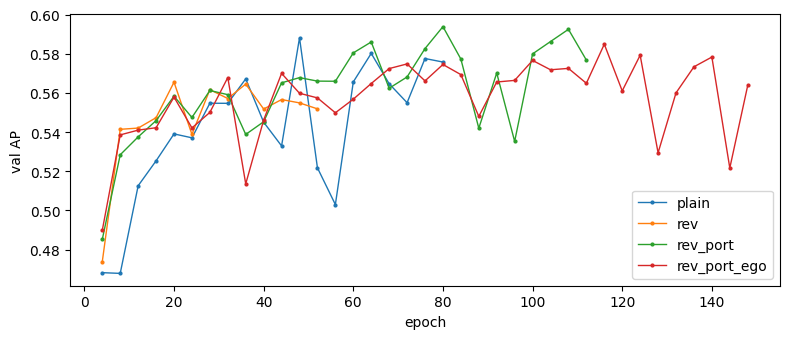

In [49]:
# 학습 곡선 — 조건별 검증 AP. 출렁임 폭이 조건 간 차이보다 크면 그 차이는 믿지 않는다
fig, ax = plt.subplots(figsize=(8, 3.5))
for c in ORDER:
    h = pd.read_csv(OUT_DIR / f'{c}_history.csv').dropna(subset=['AP']); ax.plot(h['epoch'], h['AP'], marker='.', ms=4, lw=1, label=c)
ax.set_xlabel('epoch'); ax.set_ylabel('val AP'); ax.legend(); plt.tight_layout(); plt.savefig(OUT_DIR / 'curves.png', dpi=120); plt.show()

## 7. 패턴 기준 지표 — 08 과 같은 계산
무패턴 양성은 정답도 오답도 아닌 것으로 두고 알림에서 뺀다. 알림 수는 조건마다 같다 (테스트 전체 상위 0.1% · 1%)

In [50]:
scores = {c: B.load_scores(OUT_DIR / f'{c}_test_scores.parquet') for c in ALL}
ref_ids = scores[ORDER[0]]['edge_id'].to_numpy()
for c in ALL:
    assert np.array_equal(scores[c]['edge_id'].to_numpy(), ref_ids), f'{c} 점수의 행 순서가 다르다'
lab = B.pattern_array(scores[ORDER[0]])                       # 'NORMAL' · 'UNMATCHED' · 패턴 이름
is_normal, is_un = lab == 'NORMAL', lab == 'UNMATCHED'
is_pat = ~is_normal & ~is_un
# 결제방식(ACH 여부) 은 평가에서만 쓴다
con = L.connect(threads=8, memory='3GB')
a, b = L.parse_window(cfg.test_window)
fmt = con.execute(f'''SELECT edge_id, (payment_format = 'ACH') AS is_ach FROM read_parquet({L.q(cfg.tx_path)})
                      WHERE day BETWEEN DATE {L.q(a)} AND DATE {L.q(b)} ORDER BY edge_id''').fetchnumpy()
con.close()
pos = np.minimum(np.searchsorted(fmt['edge_id'], ref_ids), len(fmt['edge_id']) - 1)
assert (fmt['edge_id'][pos] == ref_ids).all()
is_ach = np.asarray(fmt['is_ach'], dtype=bool)[pos]; del fmt, pos
print(f'테스트 {len(lab):,}건 · 패턴 {int(is_pat.sum()):,} · 무패턴 {int(is_un.sum()):,} · 정상 {int(is_normal.sum()):,}')

테스트 26,808,230건 · 패턴 20,187 · 무패턴 14,273 · 정상 26,773,770


In [51]:
rows = []
for c in ALL:
    s = scores[c]['score'].to_numpy()
    r = {'조건': c}
    for budget in (0.001, 0.01):
        k = f'{budget * 100:g}%'
        hit = s >= np.quantile(s, 1 - budget)
        tp_pat, tp_un, fp = int((hit & is_pat).sum()), int((hit & is_un).sum()), int((hit & is_normal).sum())
        r.update({f'알림@{k}': int(hit.sum()), f'패턴R@{k}': tp_pat / max(int(is_pat.sum()), 1), f'패턴P@{k}': tp_pat / max(tp_pat + fp, 1),
                  f'무패턴R@{k}': tp_un / max(int(is_un.sum()), 1), f'정상오탐@{k}': fp, f'비ACH알림@{k}': int((hit & ~is_ach).sum())})
    rows.append(r)
pat_tbl = pd.DataFrame(rows).set_index('조건')
pat_tbl.to_csv(OUT_DIR / 'pattern_metrics.csv', encoding='utf-8-sig')
pat_tbl.round(4)

,알림@0.1%,패턴R@0.1%,패턴P@0.1%,무패턴R@0.1%,정상오탐@0.1%,비ACH알림@0.1%,알림@1%,패턴R@1%,패턴P@1%,무패턴R@1%,정상오탐@1%,비ACH알림@1%
조건,,,,,,,,,,,,
plain,26809,0.9055,0.6841,0.0063,8440,3063,324380,0.9941,0.0628,0.3547,299251,121092
rev,26809,0.9151,0.7015,0.0333,7861,1760,268083,0.9954,0.0764,0.3498,242997,46096
rev_port,26809,0.9425,0.7173,0.0199,7499,1812,268083,0.9913,0.0757,0.2730,244175,137659
rev_port_ego,26809,0.9413,0.7161,0.0190,7535,1190,268083,0.9909,0.0760,0.3472,243125,104210
lightgbm,26809,0.8216,0.6243,0.0170,9981,8221,268083,0.9733,0.0737,0.1156,246786,228352
xgboost,26809,0.8103,0.6145,0.0133,10262,8762,268083,0.9792,0.0742,0.1289,246476,222848
lightgbm_nocum,26809,0.7616,0.5939,0.0644,10515,6177,268083,0.9009,0.0686,0.1954,247108,182891
xgboost_nocum,26809,0.7615,0.5935,0.0635,10530,6190,268083,0.8927,0.0678,0.1642,247719,196801


## 8. 패턴 유형별 · 수신 계좌 차수별

In [52]:
# 패턴 유형별 recall — 상위 0.1% · 1% 컷과 확률 0.5. 어느 장치가 어느 패턴을 살리나
pat = pd.concat([B.pattern_recall(scores[c]).assign(cond=c) for c in ALL])
pat.to_csv(OUT_DIR / 'analysis_pattern.csv', encoding='utf-8-sig')
order_p = [p for p in B.PATTERN_ORDER + ['ALL'] if p in pat.index]
for col in ('r@0.1%', 'r@1%', 'argmax'):
    print(f'--- {col}'); display(pat.reset_index().pivot(index='pattern_type', columns='cond', values=col).loc[order_p, ALL].round(4))

--- r@0.1%


cond,plain,rev,rev_port,rev_port_ego,lightgbm,xgboost,lightgbm_nocum,xgboost_nocum
pattern_type,,,,,,,,
FAN-OUT,0.9334,0.9334,0.9550,0.9601,0.8207,0.8494,0.7790,0.7804
FAN-IN,0.9485,0.9240,0.9646,0.9532,0.8476,0.8439,0.7612,0.7601
GATHER-SCATTER,0.9577,0.9345,0.9620,0.9577,0.8468,0.8423,0.7575,0.7575
SCATTER-GATHER,0.9450,0.9365,0.9604,0.9501,0.8404,0.8407,0.7479,0.7458
CYCLE,0.8586,0.9088,0.9250,0.9385,0.7965,0.7598,0.7242,0.7242
RANDOM,0.8524,0.9011,0.9311,0.9326,0.8022,0.7760,0.7603,0.7573
BIPARTITE,0.8385,0.8625,0.9002,0.8947,0.7752,0.7540,0.7632,0.7676
STACK,0.8435,0.8900,0.9171,0.9249,0.8042,0.7681,0.7911,0.7914
UNMATCHED,0.0063,0.0333,0.0199,0.0190,0.0170,0.0133,0.0644,0.0635


--- r@1%


cond,plain,rev,rev_port,rev_port_ego,lightgbm,xgboost,lightgbm_nocum,xgboost_nocum
pattern_type,,,,,,,,
FAN-OUT,0.9944,0.9944,0.9925,0.9906,0.9667,0.9784,0.9137,0.9122
FAN-IN,0.9932,0.9958,0.9917,0.9922,0.9865,0.9875,0.9058,0.8923
GATHER-SCATTER,0.9966,0.9974,0.9966,0.9923,0.9770,0.9815,0.9004,0.8954
SCATTER-GATHER,0.9954,0.9959,0.9897,0.9879,0.9753,0.9805,0.8980,0.8874
CYCLE,0.9946,0.9951,0.9876,0.9903,0.9709,0.9784,0.8602,0.8478
RANDOM,0.9895,0.9948,0.9903,0.9903,0.9700,0.9783,0.8787,0.8749
BIPARTITE,0.9891,0.9907,0.9913,0.9902,0.9667,0.9744,0.9143,0.9067
STACK,0.9942,0.9959,0.9889,0.9930,0.9695,0.9744,0.9174,0.9075
UNMATCHED,0.3547,0.3498,0.2730,0.3472,0.1156,0.1289,0.1954,0.1642


--- argmax


cond,plain,rev,rev_port,rev_port_ego,lightgbm,xgboost,lightgbm_nocum,xgboost_nocum
pattern_type,,,,,,,,
FAN-OUT,0.9817,0.9381,0.9672,0.9531,0.9399,0.9550,0.8081,0.8062
FAN-IN,0.9834,0.9308,0.9714,0.9407,0.9729,0.9672,0.7898,0.7836
GATHER-SCATTER,0.9852,0.9406,0.9723,0.9482,0.9585,0.9604,0.7913,0.7815
SCATTER-GATHER,0.9848,0.9429,0.9704,0.9419,0.9589,0.9625,0.7813,0.7749
CYCLE,0.9703,0.9153,0.9471,0.9255,0.9525,0.9487,0.7620,0.7458
RANDOM,0.9566,0.9079,0.9483,0.9213,0.9536,0.9543,0.7918,0.7798
BIPARTITE,0.9580,0.8680,0.9313,0.8822,0.9482,0.9433,0.8003,0.7960
STACK,0.9619,0.8964,0.9374,0.9130,0.9511,0.9517,0.8263,0.8199
UNMATCHED,0.0494,0.0343,0.0369,0.0130,0.0860,0.0851,0.0711,0.0692


### 8.1 장치마다 노린 패턴이 올랐나
Multi-GNN 논문(4절 · Table 1) 이 각 장치로 풀린다고 한 패턴을 기준으로, **그 장치를 켠 단계에서 그 패턴이 올랐는지** 본다.

| 켠 조건 | 장치 | 논문이 말하는 대상 | 여기서 볼 패턴 |
|---|---|---|---|
| `rev` | reverse MP | 나가는 간선 수(degree-out). port 와 같이 쓰면 fan-out | FAN-OUT |
| `rev_port` | port numbering | 같은 상대의 여러 거래와 서로 다른 상대를 구분 → fan-in. reverse MP 와 같이 fan-out | FAN-IN, FAN-OUT |
| `rev_port_ego` | ego ID | 혼자서는 짧은 사이클만. 셋을 다 켜야 긴 사이클 · scatter-gather · biclique | CYCLE, SCATTER-GATHER, BIPARTITE |

- GATHER-SCATTER · STACK · RANDOM · UNMATCHED 는 논문에 대응이 없어 표시하지 않는다
- BIPARTITE 는 이 데이터에서 논문 정의와 다르게 생성됐다는 팀 확인이 있어 참고만 한다
- 논문의 합성 실험은 피처 없이 구조만 맞히는 과제다. 여기는 쌍 이력 · 계좌 이력 피처(누적 건수, 서로 다른 상대 수) 가 이미 차수 정보를 담고 있어서 장치의 몫이 논문보다 작게 나올 수 있다
- 표의 열 = 켠 조건, 값 = 바로 앞 조건 대비 차이, **◎ = 노린 칸**. 시드가 하나라 작은 차이는 읽지 않는다

In [53]:
# 장치마다 노린 패턴 (위 표). 조건 이름 = 그 장치를 켠 단계
INTENDED = {'rev': ['FAN-OUT'], 'rev_port': ['FAN-IN', 'FAN-OUT'], 'rev_port_ego': ['CYCLE', 'SCATTER-GATHER', 'BIPARTITE']}
STEPS = [(ORDER[k - 1], ORDER[k]) for k in range(1, len(ORDER))]
n_by_pattern = pat[pat.cond == ORDER[0]]['n'].astype(int)


def step_delta(wide):
    # 행 = 패턴, 열 = 조건인 표 → 바로 앞 조건 대비 차이 (열 이름 = 켠 조건)
    return pd.DataFrame({b: wide[b] - wide[a] for a, b in STEPS})


def mark_intended(delta):
    # 노린 칸에 ◎ 를 붙인다 (보기용 문자열 표)
    out = delta.round(4).astype(str)
    for cond, pats in INTENDED.items():
        for p_ in pats:
            if cond in out.columns and p_ in out.index:
                out.loc[p_, cond] = '◎ ' + out.loc[p_, cond]
    return out


# 패턴별 recall 의 단계별 변화 — 상위 0.1% 컷과 확률 0.5
for col in ('r@0.1%', 'argmax'):
    wide = pat.reset_index().pivot(index='pattern_type', columns='cond', values=col).loc[order_p, ORDER]
    print(f'--- {col} recall: 앞 조건 대비 차이'); display(mark_intended(step_delta(wide)).assign(n=n_by_pattern))

--- r@0.1% recall: 앞 조건 대비 차이


,rev,rev_port,rev_port_ego,n
pattern_type,,,,
FAN-OUT,◎ 0.0,◎ 0.0216,0.0051,2131
FAN-IN,-0.0245,◎ 0.0406,-0.0114,1922
GATHER-SCATTER,-0.0232,0.0275,-0.0043,3785
SCATTER-GATHER,-0.0085,0.0239,◎ -0.0103,3891
CYCLE,0.0502,0.0162,◎ 0.0135,1853
RANDOM,0.0487,0.03,0.0015,1335
BIPARTITE,0.024,0.0377,◎ -0.0055,1833
STACK,0.0465,0.0271,0.0078,3437
UNMATCHED,0.027,-0.0134,-0.0009,14273


--- argmax recall: 앞 조건 대비 차이


,rev,rev_port,rev_port_ego,n
pattern_type,,,,
FAN-OUT,◎ -0.0436,◎ 0.0291,-0.0141,2131
FAN-IN,-0.0526,◎ 0.0406,-0.0307,1922
GATHER-SCATTER,-0.0446,0.0317,-0.0241,3785
SCATTER-GATHER,-0.0419,0.0275,◎ -0.0285,3891
CYCLE,-0.055,0.0318,◎ -0.0216,1853
RANDOM,-0.0487,0.0404,-0.027,1335
BIPARTITE,-0.09,0.0633,◎ -0.0491,1833
STACK,-0.0655,0.041,-0.0244,3437
UNMATCHED,-0.0151,0.0026,-0.0239,14273


In [54]:
# 패턴별 AP — 그 패턴의 양성 vs 정상만 놓고 본 AP (다른 패턴 · 무패턴 양성은 뺀다)
# 컷을 정하지 않는 지표라, recall 이 컷에서 포화돼 차이가 안 보일 때 이쪽을 본다. 값이 작아 보여도 정상이다 (양성이 수백 ~ 수천 건 / 정상 2,677만 건)
lab_code, lab_names = pd.factorize(lab); lab_code = lab_code.astype(np.int8)
normal_code = list(lab_names).index('NORMAL')
PATS = [p_ for p_ in B.PATTERN_ORDER if p_ in set(lab_names)]


def pattern_ap(score):
    order = np.argsort(-score, kind='stable')                    # 점수 높은 순 (동점은 원래 순서)
    code_s = lab_code[order]; cum_normal = np.cumsum(code_s == normal_code)
    out = {}
    for p_ in PATS:
        idx = np.flatnonzero(code_s == list(lab_names).index(p_))  # 점수순에서 이 패턴 양성이 나오는 자리
        k = np.arange(1, len(idx) + 1)
        out[p_] = float(np.mean(k / (k + cum_normal[idx])))        # 그 자리까지의 precision 을 평균 = AP
    return out


ap_wide = pd.DataFrame({c: pattern_ap(scores[c]['score'].to_numpy()) for c in ALL}).loc[PATS, ALL]
ap_wide.to_csv(OUT_DIR / 'analysis_pattern_ap.csv', encoding='utf-8-sig')
print('--- 패턴별 AP (패턴 vs 정상)'); display(ap_wide.round(4).assign(n=n_by_pattern))
print('--- 앞 조건 대비 차이'); display(mark_intended(step_delta(ap_wide)).assign(n=n_by_pattern))

--- 패턴별 AP (패턴 vs 정상)


,plain,rev,rev_port,rev_port_ego,lightgbm,xgboost,lightgbm_nocum,xgboost_nocum,n
FAN-OUT,0.5193,0.4534,0.5388,0.4792,0.6130,0.6354,0.5026,0.5084,2131
FAN-IN,0.5190,0.4160,0.5596,0.4235,0.5827,0.5863,0.4452,0.4416,1922
GATHER-SCATTER,0.7074,0.5996,0.7042,0.6243,0.6743,0.6848,0.5515,0.5538,3785
SCATTER-GATHER,0.6707,0.5999,0.6779,0.6121,0.6475,0.6579,0.5347,0.5371,3891
CYCLE,0.3346,0.3390,0.3871,0.3784,0.4095,0.3641,0.3605,0.3604,1853
RANDOM,0.2727,0.2702,0.3212,0.2977,0.3688,0.3198,0.3314,0.3335,1335
BIPARTITE,0.3269,0.3065,0.3841,0.3335,0.4609,0.4052,0.4165,0.4128,1833
STACK,0.4435,0.4497,0.5156,0.4759,0.5443,0.4788,0.5421,0.5344,3437
UNMATCHED,0.0129,0.0165,0.0141,0.0172,0.0068,0.0070,0.0144,0.0138,14273


--- 앞 조건 대비 차이


,rev,rev_port,rev_port_ego,n
FAN-OUT,◎ -0.0659,◎ 0.0853,-0.0596,2131
FAN-IN,-0.103,◎ 0.1436,-0.1362,1922
GATHER-SCATTER,-0.1078,0.1046,-0.0799,3785
SCATTER-GATHER,-0.0708,0.078,◎ -0.0658,3891
CYCLE,0.0043,0.0481,◎ -0.0087,1853
RANDOM,-0.0025,0.051,-0.0235,1335
BIPARTITE,-0.0204,0.0776,◎ -0.0506,1833
STACK,0.0062,0.0658,-0.0397,3437
UNMATCHED,0.0036,-0.0024,0.0031,14273


In [ ]:
# 수신 계좌 in-degree 구간별 AP — 허브 구간에서 어느 장치가 도움이 되나
if 'test_df' not in globals() or 'in_degree' not in globals():
    con = L.connect(threads=8, memory='12GB')
    test_df = B.test_full(con, cfg.test_window); in_degree = B.recipient_indegree(con, cfg); con.close()
test_dst = pd.Series(test_df['dst'].to_numpy(), index=test_df['edge_id'].to_numpy()).reindex(ref_ids).to_numpy()   # 점수 행 순서에 맞춘 dst
deg = pd.concat([B.degree_stratified(scores[c], test_dst, in_degree).assign(cond=c) for c in ALL])
deg.to_csv(OUT_DIR / 'analysis_degree.csv', encoding='utf-8-sig')
bins = [f'[{lo}-{hi}]' if hi < 10**9 else f'[{lo}+]' for lo, hi in B.DEGREE_BINS]
deg.reset_index().pivot(index='bin', columns='cond', values='AP').loc[[b for b in bins if b in deg.index], ALL].round(4)

## 10. 진단 — 트리는 왜 비ACH 를 알리나
같은 20열인데 트리(`lightgbm`) 는 상위 0.1% 알림 중 비ACH 가 8,221건, GINe(`rev_port_ego`) 는 1,190건이다. 누적 피처를 빼도(`nocum`) 6,177건이라 누적 드리프트가 원인은 아니었다. 그 알림이 **어떤 거래인지** 직접 본다 (학습 없음. 7 절까지 돌린 상태에서 실행)

| 절 | 보는 것 | 가르는 것 |
|---|---|---|
| 10.1 | 알림의 구성 (ACH · 비ACH × 패턴 · 무패턴 · 정상) | 비ACH 알림이 정말 전부 오탐인가. 트리는 ACH 쪽 오탐이 적은가 |
| 10.2 | 비ACH 오탐의 날짜 · 결제방식 | 며칠 · 한 결제방식에 몰려 있나 (그 기간의 거래 묶음) vs 고르게 퍼져 있나 |
| 10.3 | 점수 순위 안의 위치, 계좌 쏠림, 패턴 계좌와의 관계 | "패턴 사이에 한 덩어리로 끼어 있다" 는 그림이 맞나. 몇몇 계좌가 만드나. GNN 의 ACH 오탐은 패턴 계좌의 다른 거래인가 |
| 10.4 | 오탐 거래의 피처 값 (잡은 패턴 · 보통의 비ACH 정상 거래와 비교) | 트리가 어느 피처를 보고 속았나 |
| 10.5 | 그 피처 조건에 걸리는 비ACH 정상 거래의 비율을 2주 단위로 | 시간이 갈수록 서서히 느나 (경과 시간에 묶인 피처) vs 테스트 2주에만 튀나 |

In [ ]:
DIAG_TREE, DIAG_GNN, DIAG_BUDGET = 'lightgbm', 'rev_port_ego', 0.001      # 비교할 두 모델과 알림 예산 (테스트 전체 상위 0.1%)
assert DIAG_TREE in scores and DIAG_GNN in scores, '7 절을 먼저 돌린다 (트리 점수는 5.1 절)'
con = L.connect(threads=8, memory='6GB')
FORMATS = [r[0] for r in con.execute(f"SELECT DISTINCT payment_format FROM read_parquet({L.q(cfg.tx_path)}) ORDER BY 1").fetchall()]
ACH = FORMATS.index('ACH')


def window_meta(con, a, b):
    # 기간 a ~ b 거래의 edge_id · 날짜(기간 첫날부터 며칠째) · 결제방식 번호 · 라벨 · 양끝 계좌를 edge_id 순 numpy 로 (문자열을 안 들고 와서 가볍다)
    case = ' '.join(f'WHEN {L.q(f)} THEN {k}' for k, f in enumerate(FORMATS))
    return con.execute(f'''
        SELECT edge_id, datediff('day', DATE {L.q(a)}, day)::SMALLINT AS d, (CASE payment_format {case} END)::TINYINT AS fmt,
               is_laundering::TINYINT AS y, src::INT AS src, dst::INT AS dst
        FROM read_parquet({L.q(cfg.tx_path)}) WHERE day BETWEEN DATE {L.q(a)} AND DATE {L.q(b)} ORDER BY edge_id''').fetchnumpy()


T_A, T_B = L.parse_window(cfg.test_window)
meta = window_meta(con, T_A, T_B); con.close()
pos = np.minimum(np.searchsorted(meta['edge_id'], ref_ids), len(meta['edge_id']) - 1)
assert (meta['edge_id'][pos] == ref_ids).all()
meta = {k: np.asarray(v)[pos] for k, v in meta.items()}                    # 점수 행 순서에 맞춘다 (smoke 처럼 테스트 일부만 있을 때도)
assert ((meta['fmt'] == ACH) == is_ach).all(), '7 절의 is_ach 와 다르다'

s_tree, s_gnn = scores[DIAG_TREE]['score'].to_numpy(), scores[DIAG_GNN]['score'].to_numpy()
hit_tree, hit_gnn = s_tree >= np.quantile(s_tree, 1 - DIAG_BUDGET), s_gnn >= np.quantile(s_gnn, 1 - DIAG_BUDGET)


def compose(hit):
    kinds = (is_pat, is_un, is_normal)
    return pd.DataFrame({'ACH': [int((hit & g & is_ach).sum()) for g in kinds], '비ACH': [int((hit & g & ~is_ach).sum()) for g in kinds]}, index=['패턴', '무패턴', '정상 (오탐)'])


comp = pd.concat({DIAG_TREE: compose(hit_tree), DIAG_GNN: compose(hit_gnn)}, axis=1)
comp.loc['합계'] = comp.sum()
comp.to_csv(OUT_DIR / 'diag_alert_composition.csv', encoding='utf-8-sig')
print(f'상위 {DIAG_BUDGET * 100:g}% 알림의 구성 (건)'); comp

### 10.2 비ACH 오탐은 언제 · 어떤 결제방식인가
`만 건당` = 그날(그 결제방식) 의 정상 거래 1만 건 중 알림이 뜬 수. 날짜별 값이 비슷하면 고르게 퍼진 것이고, 며칠만 튀면 그 날짜의 거래 묶음이다

In [ ]:
fp_tree, fp_gnn = hit_tree & is_normal & ~is_ach, hit_gnn & is_normal & ~is_ach      # 비ACH 정상 거래에 뜬 알림
base_nonach = is_normal & ~is_ach
n_day = int(meta['d'].max()) + 1
by_day = pd.DataFrame({'비ACH 정상 거래': np.bincount(meta['d'][base_nonach], minlength=n_day), f'{DIAG_TREE} 오탐': np.bincount(meta['d'][fp_tree], minlength=n_day),
                       f'{DIAG_GNN} 오탐': np.bincount(meta['d'][fp_gnn], minlength=n_day)}, index=pd.date_range(T_A, periods=n_day))
by_day.insert(0, '요일', by_day.index.day_name().str[:3])
for m_ in (DIAG_TREE, DIAG_GNN):
    by_day[f'{m_} 만 건당'] = (by_day[f'{m_} 오탐'] / by_day['비ACH 정상 거래'].clip(lower=1) * 1e4).round(2)
by_day.index = by_day.index.strftime('%m-%d'); by_day.to_csv(OUT_DIR / 'diag_fp_by_day.csv', encoding='utf-8-sig')
by_day

In [ ]:
# 결제방식별 (ACH 포함 — 정상 거래 전체 기준)
n_fmt = len(FORMATS)
by_fmt = pd.DataFrame({'정상 거래': np.bincount(meta['fmt'][is_normal], minlength=n_fmt), '세탁 거래': np.bincount(meta['fmt'][~is_normal], minlength=n_fmt),
                       f'{DIAG_TREE} 오탐': np.bincount(meta['fmt'][hit_tree & is_normal], minlength=n_fmt),
                       f'{DIAG_GNN} 오탐': np.bincount(meta['fmt'][hit_gnn & is_normal], minlength=n_fmt)}, index=FORMATS)
for m_ in (DIAG_TREE, DIAG_GNN):
    by_fmt[f'{m_} 만 건당'] = (by_fmt[f'{m_} 오탐'] / by_fmt['정상 거래'].clip(lower=1) * 1e4).round(2)
by_fmt.to_csv(OUT_DIR / 'diag_fp_by_format.csv', encoding='utf-8-sig')
by_fmt

### 10.3 순위 안의 위치 · 계좌 쏠림 · 패턴 계좌와의 관계
- **순위 구간**: 알림을 점수 높은 순으로 10등분해 구간마다 무엇이 들어 있나. 트리의 비ACH 오탐이 가운데 구간에 몰려 있으면 "패턴 사이에 끼어 있다" 는 그림이 맞다
- **계좌 쏠림**: 오탐 거래의 송신 · 수신 계좌가 몇 개인가. 상위 10개 계좌가 대부분이면 몇몇 계좌의 문제다
- **패턴 계좌**: 테스트 구간 패턴 거래의 양끝 계좌. 오탐 거래의 한쪽이 패턴 계좌면 "세탁에 낀 계좌의 다른 거래" 를 잡은 것이다

In [ ]:
def rank_bins(s, hit, n_bins=10):
    idx = np.flatnonzero(hit); order = idx[np.argsort(-s[idx], kind='stable')]                 # 알림을 점수 높은 순으로
    b = np.minimum(np.arange(len(order)) * n_bins // len(order), n_bins - 1) + 1
    kind = np.select([is_pat[order], is_un[order], is_normal[order] & ~is_ach[order]], ['패턴', '무패턴', '정상 비ACH'], '정상 ACH')
    return pd.crosstab(pd.Series(b, name='순위 구간 (1 = 최상위)'), pd.Series(kind, name='')).reindex(columns=['패턴', '무패턴', '정상 ACH', '정상 비ACH'], fill_value=0)


for m_, s_, h_ in ((DIAG_TREE, s_tree, hit_tree), (DIAG_GNN, s_gnn, hit_gnn)):
    print(f'--- {m_}: 알림을 점수순 10등분'); display(rank_bins(s_, h_))

In [ ]:
pat_accts = np.unique(np.concatenate([meta['src'][is_pat], meta['dst'][is_pat]]))            # 테스트 구간 패턴 거래의 양끝 계좌
src_in_pat, dst_in_pat = np.isin(meta['src'], pat_accts), np.isin(meta['dst'], pat_accts)


def top_share(a, k=10):
    c = np.sort(np.unique(a, return_counts=True)[1])[::-1]
    return c[:k].sum() / max(c.sum(), 1)


groups = {f'{DIAG_TREE} 오탐 · 비ACH': hit_tree & is_normal & ~is_ach, f'{DIAG_TREE} 오탐 · ACH': hit_tree & is_normal & is_ach,
          f'{DIAG_GNN} 오탐 · 비ACH': hit_gnn & is_normal & ~is_ach, f'{DIAG_GNN} 오탐 · ACH': hit_gnn & is_normal & is_ach,
          '(기준) 정상 비ACH 전체': is_normal & ~is_ach, '(기준) 정상 ACH 전체': is_normal & is_ach}
acct = pd.DataFrame({name: {'거래': int(m.sum()), '송신 계좌 수': len(np.unique(meta['src'][m])), '수신 계좌 수': len(np.unique(meta['dst'][m])),
                            '송신 상위 10개 비중': top_share(meta['src'][m]), '수신 상위 10개 비중': top_share(meta['dst'][m]),
                            '송신이 패턴 계좌': src_in_pat[m].mean(), '수신이 패턴 계좌': dst_in_pat[m].mean(), '한쪽이라도 패턴 계좌': (src_in_pat[m] | dst_in_pat[m]).mean()}
                     for name, m in groups.items() if m.any()}).T
acct.to_csv(OUT_DIR / 'diag_fp_accounts.csv', encoding='utf-8-sig')
acct.round(4)

### 10.4 오탐 거래의 피처 값
값은 z (학습 구간 평균 0 · 표준편차 1). `차이` = 트리의 비ACH 오탐 − 보통의 비ACH 정상 거래. 차이가 큰 피처가 트리가 속은 근거다. `잡은 패턴` 과 값이 비슷한 피처일수록 "패턴처럼 보였다" 는 뜻이다

In [ ]:
import pyarrow.parquet as pq
all_ids = pq.read_table(cfg.feat_dir / 'tx_base.parquet', columns=['edge_id']).column('edge_id').to_numpy()     # 피처 행렬의 행 순서 (edge_id 순)
F = np.load(FEAT_PATH, mmap_mode='r'); base_cols = [GNN_FEATURES.index(c) for c in BASE_FEATURES]


def window_rows(ids):
    # 기간 거래가 피처 행렬에서 차지하는 연속 구간의 시작 행 (시간순이라 기간 = 연속한 행)
    start = int(np.searchsorted(all_ids, ids[0]))
    assert np.array_equal(all_ids[start:start + len(ids)], ids), '기간 거래가 피처 행렬에서 연속 구간이 아니다'
    return start


row_of = np.searchsorted(all_ids, ref_ids); assert (all_ids[row_of] == ref_ids).all()
lo, hi = int(row_of.min()), int(row_of.max()) + 1
X_test = np.asarray(F[lo:hi])[row_of - lo][:, base_cols]                   # 테스트 거래 × 20열 (float16, 약 1GB)
feat_groups = {f'{DIAG_TREE} 오탐 비ACH': fp_tree, '보통의 비ACH 정상': base_nonach, f'{DIAG_TREE} 잡은 패턴': hit_tree & is_pat, f'{DIAG_TREE} 놓친 패턴': ~hit_tree & is_pat,
               f'{DIAG_TREE} 오탐 ACH': hit_tree & is_normal & is_ach, f'{DIAG_GNN} 오탐 비ACH': fp_gnn}
feat_tab = pd.DataFrame({name: X_test[m].astype(np.float32).mean(0) if m.any() else np.nan for name, m in feat_groups.items()}, index=BASE_FEATURES)
feat_tab.insert(0, '차이', feat_tab[f'{DIAG_TREE} 오탐 비ACH'] - feat_tab['보통의 비ACH 정상'])
feat_tab = feat_tab.reindex(feat_tab['차이'].abs().sort_values(ascending=False).index)
feat_tab.to_csv(OUT_DIR / 'diag_fp_features.csv', encoding='utf-8-sig')
feat_tab.round(3)

### 10.5 그 피처 조건에 걸리는 비ACH 정상 거래 — 2주 단위 추이
10.4 에서 차이가 가장 큰 피처 3개로 "오탐과 닮은 거래" 의 조건을 만든다 (피처마다 오탐의 중앙값보다 그 방향으로 더 극단). 이 조건에 걸리는 비ACH 정상 거래가 만 건당 몇 건인지 학습 4구간 · 검증 · 테스트로 나눠 본다
- **구간마다 꾸준히 는다** → 시간이 갈수록 값이 커지는 피처 문제 (경과 시간에 묶인 피처). 학습 때는 드물던 영역에 정상 거래가 들어오는 것
- **테스트에서만 튄다** → 그 2주의 거래 묶음 문제
- **어느 구간이나 비슷하다** → 피처 분포는 그대로인데 트리가 그 영역을 잘못 배운 것 (학습 구간에서 그 영역의 세탁 비율을 같이 본다)

In [ ]:
TOP_K = 3
top_feats = list(feat_tab.index[:TOP_K])
cuts = {f: (float(np.median(X_test[fp_tree, BASE_FEATURES.index(f)].astype(np.float32))), 1 if feat_tab.loc[f, '차이'] > 0 else -1) for f in top_feats}   # (오탐 중앙값, 방향)
print('조건:', ' 그리고 '.join(f"{f} {'≥' if sg > 0 else '≤'} {c:.2f}" for f, (c, sg) in cuts.items()))
WINDOWS_2W = [('2022-08-08', '2022-08-21'), ('2022-08-22', '2022-09-04'), ('2022-09-05', '2022-09-18'), ('2022-09-19', '2022-10-02'),
              ('2022-10-03', '2022-10-16'), ('2022-10-17', '2022-10-30')]
con = L.connect(threads=8, memory='6GB'); rows = []
for a, b in WINDOWS_2W:
    m_ = window_meta(con, a, b)
    if len(m_['edge_id']) == 0:
        continue
    start = window_rows(np.asarray(m_['edge_id'])); n = len(m_['edge_id'])
    Xw = np.asarray(F[start:start + n][:, [GNN_FEATURES.index(f) for f in top_feats]])
    ok = [(Xw[:, j] >= c) if sg > 0 else (Xw[:, j] <= c) for j, (c, sg) in enumerate(cuts.values())]
    both = np.logical_and.reduce(ok); normal_nonach = (m_['y'] == 0) & (m_['fmt'] != ACH); pos_ = m_['y'] == 1
    row = {'구간': f'{a[5:]} ~ {b[5:]}', '비ACH 정상 거래': int(normal_nonach.sum())}
    for f, o in zip(top_feats, ok):
        row[f'{f} 만 건당'] = o[normal_nonach].mean() * 1e4
    row.update({'셋 다 만 건당': both[normal_nonach].mean() * 1e4, '셋 다 걸린 비ACH 정상 (건)': int((both & normal_nonach).sum()),
                '셋 다 걸린 세탁 (건)': int((both & pos_).sum()), '셋 다 걸린 거래 중 세탁 비율': (both & pos_).sum() / max(int(both.sum()), 1)})
    rows.append(row); del Xw, m_
con.close()
trend = pd.DataFrame(rows).set_index('구간'); trend.insert(0, '쓰임', ['학습'] * (len(trend) - 2) + ['검증', '테스트'] if len(trend) == len(WINDOWS_2W) else '')
trend.to_csv(OUT_DIR / 'diag_fp_trend.csv', encoding='utf-8-sig')
B.release_mmap(F)
trend.round(4)

### 10.6 읽는 순서
1. **10.1**: 트리의 비ACH 알림이 거의 전부 `정상 (오탐)` 칸에 있는지, 트리의 `정상 · ACH` 가 GNN 보다 적은지 (트리는 ACH 안에서는 정확하고 비ACH 에서만 틀린다는 그림)
2. **10.2**: 날짜별 `만 건당` 이 고른지 튀는지. 결제방식 하나가 대부분인지
3. **10.3**: 트리의 `정상 비ACH` 가 순위 가운데 구간에 몰려 있는지. 송신 · 수신 상위 10개 비중이 큰지. GNN 의 ACH 오탐에서 `한쪽이라도 패턴 계좌` 가 기준보다 훨씬 높으면 "세탁에 낀 계좌의 다른 거래를 잡는다" 는 추정이 맞다
4. **10.4 → 10.5**: 어느 피처가 다른지, 그 조건에 걸리는 비ACH 정상 거래가 시간에 따라 어떻게 변하는지. 10.5 의 `셋 다 걸린 거래 중 세탁 비율` 이 학습 구간에서 높고 테스트에서 낮으면, 학습 때는 그 영역이 세탁 위주였는데 테스트에서는 정상 거래가 들어온 것이다

## 9. 읽는 법
- **6 절의 차이 표**: 각 행이 그 장치를 켜서 얻은 몫이다. 순서를 바꾸면 몫이 달라질 수 있다 (하나씩 쌓는 비교의 한계)
- **시드가 하나다.** 학습 곡선(6 절) 에서 검증 AP 가 출렁이는 폭을 먼저 본다. 조건 간 차이가 그 폭보다 작으면 "차이 없음" 으로 읽는다
- **7 절**: 같은 알림 수에서 패턴 precision 과 무패턴 recall 이 장치에 따라 어떻게 바뀌나. 08 의 트리(`base`: 패턴 R 0.962 · P 0.759 @0.1%) 는 v10 버전 피처(구간 끝 기준 노드 값 포함) 라서 절대값을 그대로 비교하면 안 된다
- **8.1 절**: ◎ 칸(그 장치가 노린 패턴) 이 다른 칸보다 뚜렷하게 올랐으면 장치가 의도대로 작동한 것이다. ◎ 가 아닌 칸만 오르거나 전부 비슷하게 오르면 "구조를 읽어서" 가 아니라 모델 용량 · 이웃 수가 늘어난 효과일 수 있다. recall 표가 포화돼 있으면 패턴별 AP 표를 본다
- `plain` 은 역방향 층이 없어 파라미터 수가 적다. `rev` 와의 차이에는 "역방향 메시지" 와 "층이 늘어난 것" 이 같이 들어 있다
- port 를 끈 조건도 `in_port` · `out_port` 열 자리는 남아 있다 (값만 0). 입력 차원은 네 조건이 같다
- 차이가 작게 나오면: 이 피처 셋(쌍 이력 · 계좌 이력) 이 구조 정보를 이미 담고 있어서일 수 있다. 06 에서 같은 피처로 트리(LightGBM 테스트 AP 0.634) 가 GINe(0.583) 를 넘었다
- **트리 행 (`lightgbm` · `xgboost`)**: GNN 과 같은 20열이다. 트리가 GNN 과 같거나 높으면 "이 피처가 있을 때 그래프를 읽어서 더 얻는 것은 없다" 는 뜻이고, GNN 이 높은 지표 · 패턴이 있으면 거기가 그래프의 몫이다. 트리는 port · ego · 이웃을 전혀 쓰지 않는다
- **`_nocum` 행**: 누적 8열을 뺀 트리. `test−val` 이 20열 트리(−0.135) 보다 뚜렷이 작으면 누적 피처의 드리프트가 테스트 붕괴의 원인이다. 5.1.1 의 표에서 누적 피처가 테스트로 갈수록 밀리는지도 같이 본다. 똑같이 무너지면 원인은 다른 데 있다 (비ACH 알림 수를 7 절에서 확인)